In [24]:
import pandas as pd
import numpy as np
import seaborn as sns

df = pd.read_csv("../../data/counters_raw.csv", low_memory=False, na_values=['na'], index_col=0)
df.loc[:, 'datetime'] = pd.to_datetime(df.loc[:, "iso_timestamp"], utc=True)
df = df.drop(columns=["iso_timestamp"])

In [25]:
df.nunique(dropna=False)

operator_name                 1
domain_name                  16
domain_id                    16
counter_site                 69
counter_site_id              68
counter_serial               71
longitude                    70
latitude                     70
timezone                      1
channels_in                 965
channels_out                883
channels_unknown           1430
channels_all               1534
site_temperature             62
site_rain_accumulation      174
site_snow_accumulation        1
datetime                  51119
dtype: int64

operator_name, timezone and site_snow_accumulation have no information, so they are out

In [26]:
df = df.drop(labels=["timezone", "operator_name", "site_snow_accumulation"], axis=1)

Now let's look for functional dependencies

<Axes: >

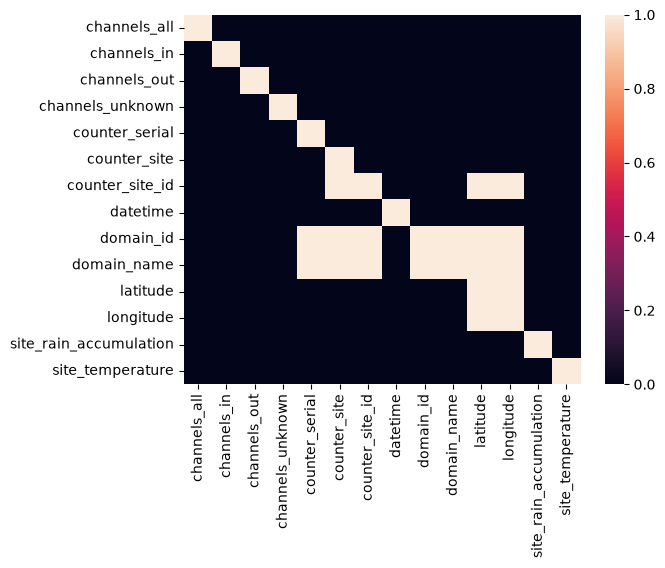

In [27]:
dependencies = pd.DataFrame({col: df.groupby(by=col).nunique(dropna=False).max() == 1 for col in df.columns})
dependencies = dependencies.fillna(True)
dependencies = dependencies.astype(np.bool)
dependencies = dependencies.sort_index()
dependencies = dependencies[sorted(dependencies.columns)]
sns.heatmap(dependencies)

Some findings:
* counter_site determines counter_site_id, but *not* the other way round. It seems some site name has two possible IDs: maybe the counter was modified at some point
* counter_side_id (but *not* counter_site) determines the coordinates and the domain_id/domain_name
* counter_serial determines domain_id/domain_name, but not the individual counter location

In [28]:
location_cols = ['domain_id', 'domain_name', 'counter_site_id', 'counter_site', 'counter_serial', 'latitude', 'longitude']
location_data = df.loc[:, location_cols].drop_duplicates(keep='first').reset_index(drop=True).reset_index()
location_data = location_data.rename(columns={'index': 'location_index'})
location_data.head()

,location_index,domain_id,domain_name,counter_site_id,counter_site,counter_serial,latitude,longitude
0,0,667,Stadt Tübingen,100003358,Fuß- & Radtunnel Südportal - Derendinger Allee,YTH24052174,48.518000,9.048060
1,1,667,Stadt Tübingen,100003359,Unterführung Steinlach/Karlstraße Südseite - S...,ZLT26053560,48.515434,9.058865
2,2,752,Stadt Karlsruhe,100004165,Erbprinzenstraße,Y2H16070301,49.007286,8.402715
3,3,751,Stadt Freiburg,100004595,Wiwilibrücke,NaN,47.995213,7.840753
4,4,3938,Stadt Lörrach,100008949,Berliner Platz,YAH23060720,47.619740,7.659360


In [29]:
df = pd.merge(location_data, df, on=location_cols).drop(columns=location_cols)

In [30]:
df.count()

location_index            3360738
channels_in               3006420
channels_out              3000655
channels_unknown           353732
channels_all              3360738
site_temperature          3294170
site_rain_accumulation    3294170
datetime                  3360738
dtype: int64

<Axes: >

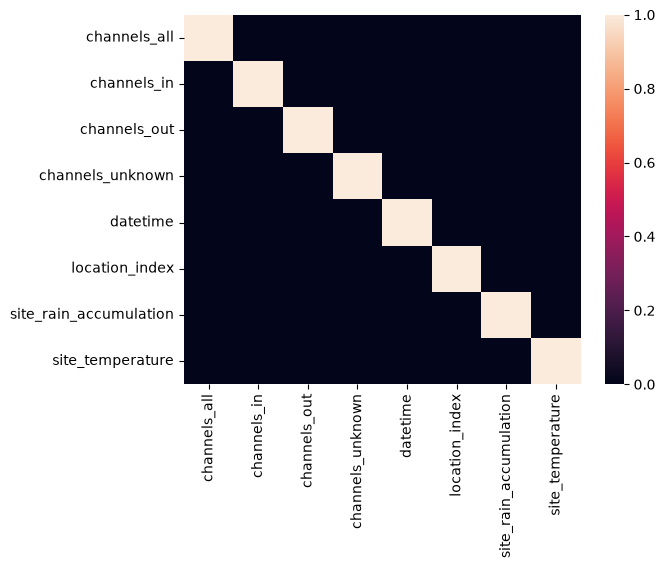

In [31]:
dependencies = pd.DataFrame({col: df.groupby(by=col).nunique(dropna=False).max() == 1 for col in df.columns})
dependencies = dependencies.fillna(True)
dependencies = dependencies.astype(np.bool)
dependencies = dependencies.sort_index()
dependencies = dependencies[sorted(dependencies.columns)]
sns.heatmap(dependencies)

In [22]:
location_data.to_csv("../../data/location_data.csv")

In [23]:
df.to_csv("../../data/counters.csv")